# Pima Diabetes: 11 untuned classifiers by ROC AUC

**On the 768 rows of the Pima Indians Diabetes data, with the same 25 cross-validation splits for every model and nothing tuned, Pairwise Difference Learning (PDL) has the highest mean ROC AUC of the 11 (0.834).** Logistic regression and CatBoost are within 0.002, so the top three are level; PDL scores higher than random forest on 20 of the 25 folds, and higher than extra trees, LightGBM and XGBoost on all 25. On 44 small datasets ([TabMini](https://github.com/Karim-53/pdll/tree/main/benchmark/tabmini)) PDL ranks 2nd of 11, behind CatBoost.

*Runs on Kaggle with Internet on (the first cell installs `pdll` from PyPI) and the dataset `uciml/pima-indians-diabetes-database` attached.*

**Pairwise Difference Learning (PDL)** trains a model on *pairs* of rows: "do these two rows have the same label?" (or, for regression, "how far apart are their targets?"). A new row is then compared with the training rows, whose labels are known, and the answers are combined. With n training rows the model can learn from up to n² pairs, which is why it is aimed at small tables. [`pdll`](https://github.com/Karim-53/pdll) wraps any scikit-learn model with the usual `fit` / `predict` API. Method: [Belaid, Rabus & Hüllermeier, *Pairwise Difference Learning for Classification*, Discovery Science 2024](https://doi.org/10.1007/978-3-031-78980-9_18). *Disclosure: I am one of the authors.*

In [ ]:
!pip install -q pdll==1.0.0 scikit-learn==1.9.1 catboost==1.2.10 lightgbm==4.7.0 xgboost==3.4.1

In [2]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import pdll
from pdll import PairwiseDifferenceClassifier

warnings.simplefilter('ignore')
N_JOBS = os.cpu_count()
DATA_DIR = os.environ.get('DATA_DIR', '/kaggle/input/pima-indians-diabetes-database')
if not os.path.exists(f'{DATA_DIR}/diabetes.csv'):   # dataset not attached: fetch it from Kaggle
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('uciml/pima-indians-diabetes-database')
data = pd.read_csv(f'{DATA_DIR}/diabetes.csv')
X, y = data.drop(columns='Outcome'), data['Outcome']
import catboost, lightgbm, sklearn, xgboost
print('pdll', pdll.__version__, '| scikit-learn', sklearn.__version__, '| catboost', catboost.__version__,
      '| lightgbm', lightgbm.__version__, '| xgboost', xgboost.__version__)
print(X.shape[0], 'rows,', X.shape[1], 'features | diabetic:', f'{y.mean():.0%}')

pdll 1.0.0 | scikit-learn 1.9.1 | catboost 1.2.10 | lightgbm 4.7.0 | xgboost 3.4.1
768 rows, 8 features | diabetic: 35%


## The 11 classifiers, all at their defaults

Only `random_state=0`, the thread count, `max_iter=1000` for logistic regression and `probability=True` for the SVM are set. Linear, k-NN and SVM models get standardized features. PDL is `PairwiseDifferenceClassifier(random_state=0)`: its default base model is an extra-trees forest with `class_weight='balanced'`.

In [3]:
def scaled(model):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), model)


MODELS = {
    'PDL (pdll)': PairwiseDifferenceClassifier(random_state=0),
    'Logistic regression': scaled(LogisticRegression(max_iter=1000)),
    'CatBoost': CatBoostClassifier(random_seed=0, thread_count=N_JOBS, verbose=0, allow_writing_files=False),
    'SVM (RBF)': scaled(SVC(probability=True, random_state=0)),
    'Random forest': RandomForestClassifier(random_state=0, n_jobs=N_JOBS),
    'Extra trees': ExtraTreesClassifier(random_state=0, n_jobs=N_JOBS),
    'XGBoost': XGBClassifier(random_state=0, n_jobs=N_JOBS),
    'LightGBM': LGBMClassifier(random_state=0, n_jobs=N_JOBS, verbose=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=0),
    'k-NN': scaled(KNeighborsClassifier(n_jobs=N_JOBS)),
    'Decision tree': DecisionTreeClassifier(random_state=0),
}

## Same 25 train/test splits for every model

5-fold stratified cross-validation repeated 5 times (about 4 minutes on a 12-thread laptop; expect 10 to 15 minutes on Kaggle's 4 CPUs).

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
scores = {name: cross_val_score(model, X, y, cv=cv, scoring='roc_auc') for name, model in MODELS.items()}
scores = pd.DataFrame(scores)
table = pd.DataFrame({'mean ROC AUC': scores.mean(), 'std over 25 folds': scores.std(),
                      'folds where PDL is higher (of 25)': ['' if m == 'PDL (pdll)' else (scores['PDL (pdll)'] > scores[m]).sum()
                                                            for m in scores.columns]})
table = table.sort_values('mean ROC AUC', ascending=False)
table.round(4)

,mean ROC AUC,std over 25 folds,folds where PDL is higher (of 25)
PDL (pdll),0.8341,0.0317,
Logistic regression,0.8322,0.0368,14
CatBoost,0.8320,0.0326,13
SVM (RBF),0.8264,0.0330,17
Random forest,0.8229,0.0342,20
Extra trees,0.8189,0.0360,25
LightGBM,0.8022,0.0323,25
HistGradientBoosting,0.8021,0.0358,24
XGBoost,0.7934,0.0330,25
k-NN,0.7782,0.0394,24


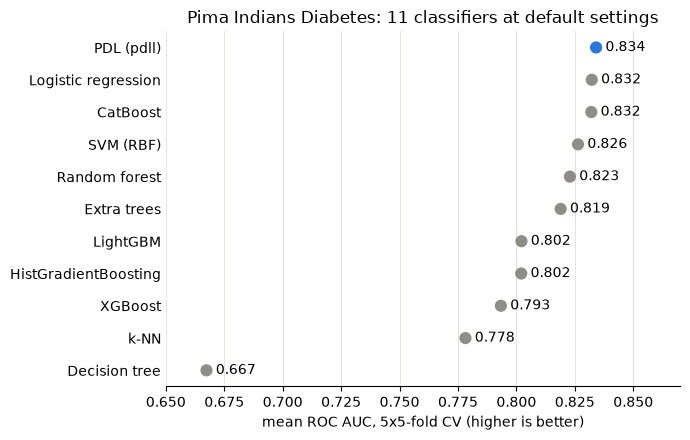

In [5]:
order = table.index[::-1]
colors = ['#2a78d6' if m == 'PDL (pdll)' else '#8f8d88' for m in order]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.grid(axis='x', color='#e6e4df', linewidth=0.8)
ax.scatter(table.loc[order, 'mean ROC AUC'], order, color=colors, s=60, zorder=3)
for i, m in enumerate(order):
    ax.text(table.loc[m, 'mean ROC AUC'] + 0.004, i, f"{table.loc[m, 'mean ROC AUC']:.3f}", va='center')
ax.set_xlim(0.65, 0.87)
ax.set_xlabel('mean ROC AUC, 5x5-fold CV (higher is better)')
ax.set_title('Pima Indians Diabetes: 11 classifiers at default settings')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

**Reading the table.** PDL has the highest mean ROC AUC (0.834), but its lead over logistic regression and CatBoost is about 0.002 and it scores higher on only 14 and 13 of the 25 folds, so treat the top three as tied. Against the other tree ensembles the gap is larger: PDL scores higher than random forest on 20 of the 25 folds, and higher than extra trees, LightGBM and XGBoost on all 25 (the folds come from 5 repeats of the same data, so these counts show consistency, not significance).

One dataset is one dataset. For the broader picture, see [TabMini](https://github.com/Karim-53/pdll/tree/main/benchmark/tabmini): 44 small binary datasets (32 to 500 rows), every one reported, where PDL at its default settings ranks 2nd of 11 by mean rank of ROC AUC, behind CatBoost, with the top group statistically close.

## Scope

- One dataset, 768 rows; one CV seed (25 folds); no model tuned.
- The data are used as published: zeros that stand for missing values (374 in Insulin, 227 in SkinThickness, 35 in BloodPressure, 11 in BMI, 5 in Glucose) are left as they are, for every model.
- TabPFN and AutoML tools are not in this comparison.

## Use it

PDL is a scikit-learn estimator, so it drops into pipelines, `cross_val_score` and `GridSearchCV` like any classifier. Five patients it has never seen:

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
model = PairwiseDifferenceClassifier(random_state=0)   # or wrap any classifier: PairwiseDifferenceClassifier(RandomForestClassifier(class_weight='balanced'))
model.fit(X_train, y_train)
model.predict_proba(X_test.head())[:, 1].round(3)      # probability of diabetes

array([0.102, 0.088, 0.115, 0.432, 0.518])

If PDL is useful in your work, please cite the paper:

```bibtex
@inproceedings{belaid2024pairwise,
  title     = {Pairwise Difference Learning for Classification},
  author    = {Belaid, Mohamed Karim and Rabus, Maximilian and H{\"u}llermeier, Eyke},
  booktitle = {Discovery Science},
  pages     = {284--299},
  publisher = {Springer},
  year      = {2024},
  doi       = {10.1007/978-3-031-78980-9_18}
}
```